# Лабораторная работа 2. Разведочный анализ данных и метод максимального правдоподобия

**Цель:** приобрести навыки визуального и статистического анализа данных, применить метод максимального правдоподобия (ММП) для оценивания параметров распределений и исследовать свойства оценок с помощью имитационного моделирования.

**Датасет:** [Cardiovascular Disease dataset](https://www.kaggle.com/datasets/sulianova/cardiovascular-disease-dataset) (Kaggle). 
| Столбец | Описание |
|---|---|
| `id` | идентификатор пациента |
| `age` | возраст, дни |
| `gender` | пол (1, 2) |
| `height` | рост, см |
| `weight` | вес, кг |
| `ap_hi`, `ap_lo` | систолическое и диастолическое артериальное давление, мм рт. ст. |
| `cholesterol`, `gluc` | холестерин и глюкоза: 1 — норма, 2 — выше нормы, 3 — значительно выше |
| `smoke`, `alco`, `active` | курение, алкоголь, физическая активность (0/1) |
| `cardio` | наличие сердечно-сосудистого заболевания (0/1) |

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import scipy.optimize as opt
from scipy.special import digamma, polygamma, gammaln

sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', lambda v: f'{v:.4f}')
pd.set_option('display.width', 200)
rng = np.random.default_rng(42)

In [3]:
DATA_PATH  = 'cardio_train.csv'
SEP        = ';'          # разделитель в исходном файле
DROP_COLS  = ['id']       # идентификатор пациента не несёт информации
NORMAL_COL = 'height'   
GENDER     = 1            
SKEWED_COL = 'weight'   
HUE_COL    = 'cardio'   
N_SIM      = 500        

## 1. Загрузка данных и первичная обработка
### 1.1. Структура данных: типы столбцов и наличие пропусков

In [4]:
df_raw = pd.read_csv(DATA_PATH, sep=SEP)
print('Размер исходных данных:', df_raw.shape)
display(df_raw.head())
df_raw.info()

Размер исходных данных: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0000,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0000,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0000,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0000,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0000,100,60,1,1,0,0,0,0


<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [5]:
df = df_raw.drop(columns=DROP_COLS)
structure = pd.DataFrame({
    'тип': df.dtypes.astype(str),
    'пропусков': df.isna().sum(),
    'уникальных значений': df.nunique(),
    'min': df.min(numeric_only=True),
    'max': df.max(numeric_only=True),
})
structure.style.format({'min': '{:g}', 'max': '{:g}'})

,тип,пропусков,уникальных значений,min,max
age,int64,0,8076,10798,23713
gender,int64,0,2,1,2
height,int64,0,109,55,250
weight,float64,0,287,10,200
ap_hi,int64,0,153,-150,16020
ap_lo,int64,0,157,-70,11000
cholesterol,int64,0,3,1,3
gluc,int64,0,3,1,3
smoke,int64,0,2,0,1
alco,int64,0,2,0,1


**Вывод.** Исходная таблица — 70 000 строк и 13 столбцов. После удаления идентификатора `id` осталось 12 признаков, все числовые: 11 целочисленных (`int64`) и вес (`float64`). Пропусков (NaN) нет ни в одном столбце.

Особенности, которые нужно учесть при обработке:
- возраст `age` записан в днях (от 10 798 до 23 713);
- категориальные признаки (`gender`, `cholesterol`, `gluc`) и бинарные (`smoke`, `alco`, `active`, `cardio`) уже закодированы числами;
- минимумы и максимумы показывают ошибки ввода: давление от −150 до 16 020 (`ap_hi`) и от −70 до 11 000 (`ap_lo`), рост от 55 до 250 см, вес от 10 кг. Они обрабатываются в п. 1.5.

### 1.2. Обработка пропусков

In [33]:
rows_with_na = df.isna().any(axis=1).mean()
print(f'Доля строк с пропусками: {rows_with_na:.2%}')

if rows_with_na == 0:
    print('Пропусков нет: удалять или заполнять нечего.')
elif rows_with_na < 0.05:
    df = df.dropna()            
else:
    num = df.select_dtypes('number').columns
    df[num] = df[num].fillna(df[num].median())   

Доля строк с пропусками: 0.00%
Пропусков нет: удалять или заполнять нечего.


**Вывод и обоснование.** Явных пропусков нет, поэтому ни удалять, ни заполнять ничего не нужно. Код содержит общее правило на случай пропусков: если строк с пропусками меньше 5%, их удаление почти не меняет выборку; если больше — числовые пропуски заполняются медианой, так как она, в отличие от среднего, устойчива к выбросам и асимметрии.

В этом датасете роль пропусков играют физиологически невозможные значения (п. 1.5): истинное значение в таких записях неизвестно. Их мы удаляем, а не заполняем медианой: замена давления 16 020 на медиану исказила бы связь `ap_hi` с `ap_lo` и с целевой переменной, а доля таких записей невелика.

### 1.3. Преобразование строковых столбцов в числовые

In [7]:
str_cols = df.select_dtypes(exclude='number').columns.tolist()
print('Строковые столбцы:', str_cols if str_cols else 'нет')
for c in str_cols:                       # факторизация, если строковые столбцы есть
    df[c], uniques = pd.factorize(df[c])
    print(f'  {c}: {dict(enumerate(uniques))}')

print('\nКатегориальные признаки уже закодированы числами:')
for c in ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']:
    print(f'  {c:12s} {sorted(df[c].unique().tolist())}')

# Возраст хранится в днях — переводим в годы (без округления, чтобы не создать ложных дубликатов)
df['age'] = df['age'] / 365.25
print(f"\nВозраст после перевода в годы: от {df['age'].min():.1f} до {df['age'].max():.1f}")

Строковые столбцы: нет

Категориальные признаки уже закодированы числами:
  gender       [1, 2]
  cholesterol  [1, 2, 3]
  gluc         [1, 2, 3]
  smoke        [0, 1]
  alco         [0, 1]
  active       [0, 1]
  cardio       [0, 1]

Возраст после перевода в годы: от 29.6 до 64.9


**Вывод.** Строковых столбцов нет, факторизация не требуется: категориальные признаки уже закодированы целыми числами. Единственное преобразование — возраст переведён из дней в годы (29,6–64,9 лет). Округлять возраст не стали намеренно: при округлении до 0,1 года разные пациенты с одинаковыми остальными признаками совпали бы, и вместо 24 настоящих дубликатов нашлось бы 674 ложных.

### 1.4. Удаление дубликатов

In [8]:
n_dup = df.duplicated().sum()
print('Полных дубликатов строк:', n_dup)
df = df.drop_duplicates().reset_index(drop=True)
print('Размер после удаления дубликатов:', df.shape)

Полных дубликатов строк: 24
Размер после удаления дубликатов: (69976, 12)


**Вывод.** Найдено 24 полных дубликата (0,03% строк). Записи совпадают по всем 11 признакам, включая возраст с точностью до дня, поэтому это почти наверняка повторно внесённые данные одного пациента. Дубликаты удалены, осталось 69 976 записей.

### 1.5. Ошибки ввода (физиологически невозможные значения)

Минимумы и максимумы в п. 1.1 показывают ошибки ввода: отрицательное давление, давление 16 020 и 11 000 мм рт. ст., рост 55 и 250 см, вес 10 кг. Это фактически «скрытые пропуски»: истинное значение неизвестно. Используем пороги, за которыми значения у взрослых практически не встречаются: систолическое давление 80–250, диастолическое 40–160 и меньше систолического, рост 130–210 см, вес 35–200 кг.

In [9]:
rules = {
    'ap_hi вне [80, 250]':  ~df['ap_hi'].between(80, 250),
    'ap_lo вне [40, 160]':  ~df['ap_lo'].between(40, 160),
    'ap_lo ≥ ap_hi':         df['ap_lo'] >= df['ap_hi'],
    'height вне [130, 210]': ~df['height'].between(130, 210),
    'weight вне [35, 200]':  ~df['weight'].between(35, 200),
}
display(pd.DataFrame({'записей': {k: int(v.sum()) for k, v in rules.items()}}))

bad = np.logical_or.reduce([v.to_numpy() for v in rules.values()])
n0 = len(df)
df = df[~bad].reset_index(drop=True)
print(f'Удалено записей: {n0 - len(df)} ({(n0 - len(df)) / n0:.1%}), осталось {len(df)}')

,записей
"ap_hi вне [80, 250]",247
"ap_lo вне [40, 160]",1025
ap_lo ≥ ap_hi,1236
"height вне [130, 210]",93
"weight вне [35, 200]",20


Удалено записей: 1441 (2.1%), осталось 68535


**Вывод.** Ошибки чаще всего связаны с давлением: у 1 236 записей диастолическое давление не меньше систолического (вероятно, поля перепутаны местами), у 1 025 — `ap_lo` вне диапазона, у 247 — `ap_hi` вне диапазона. Ошибочный рост найден в 93 записях, вес — в 20. Одна запись может нарушать несколько правил, поэтому всего удалено 1 441 запись (2,1%), осталось **68 535**.

Удаление выбрано вместо исправления, потому что однозначно восстановить значение нельзя (16 020 может быть и 160, и 120), а 2% выборки — небольшая потеря.

## 2. Разведочный анализ данных (EDA)

In [10]:
cont_cols = [c for c in df.columns if df[c].nunique() > 15]   # количественные признаки
cat_cols = [c for c in df.columns if c not in cont_cols]       # категориальные и бинарные
print('Количественные признаки:', cont_cols)
print('Категориальные/бинарные признаки:', cat_cols)

Количественные признаки: ['age', 'height', 'weight', 'ap_hi', 'ap_lo']
Категориальные/бинарные признаки: ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']


### 2.1. Гистограммы и ящики с усами для количественных признаков

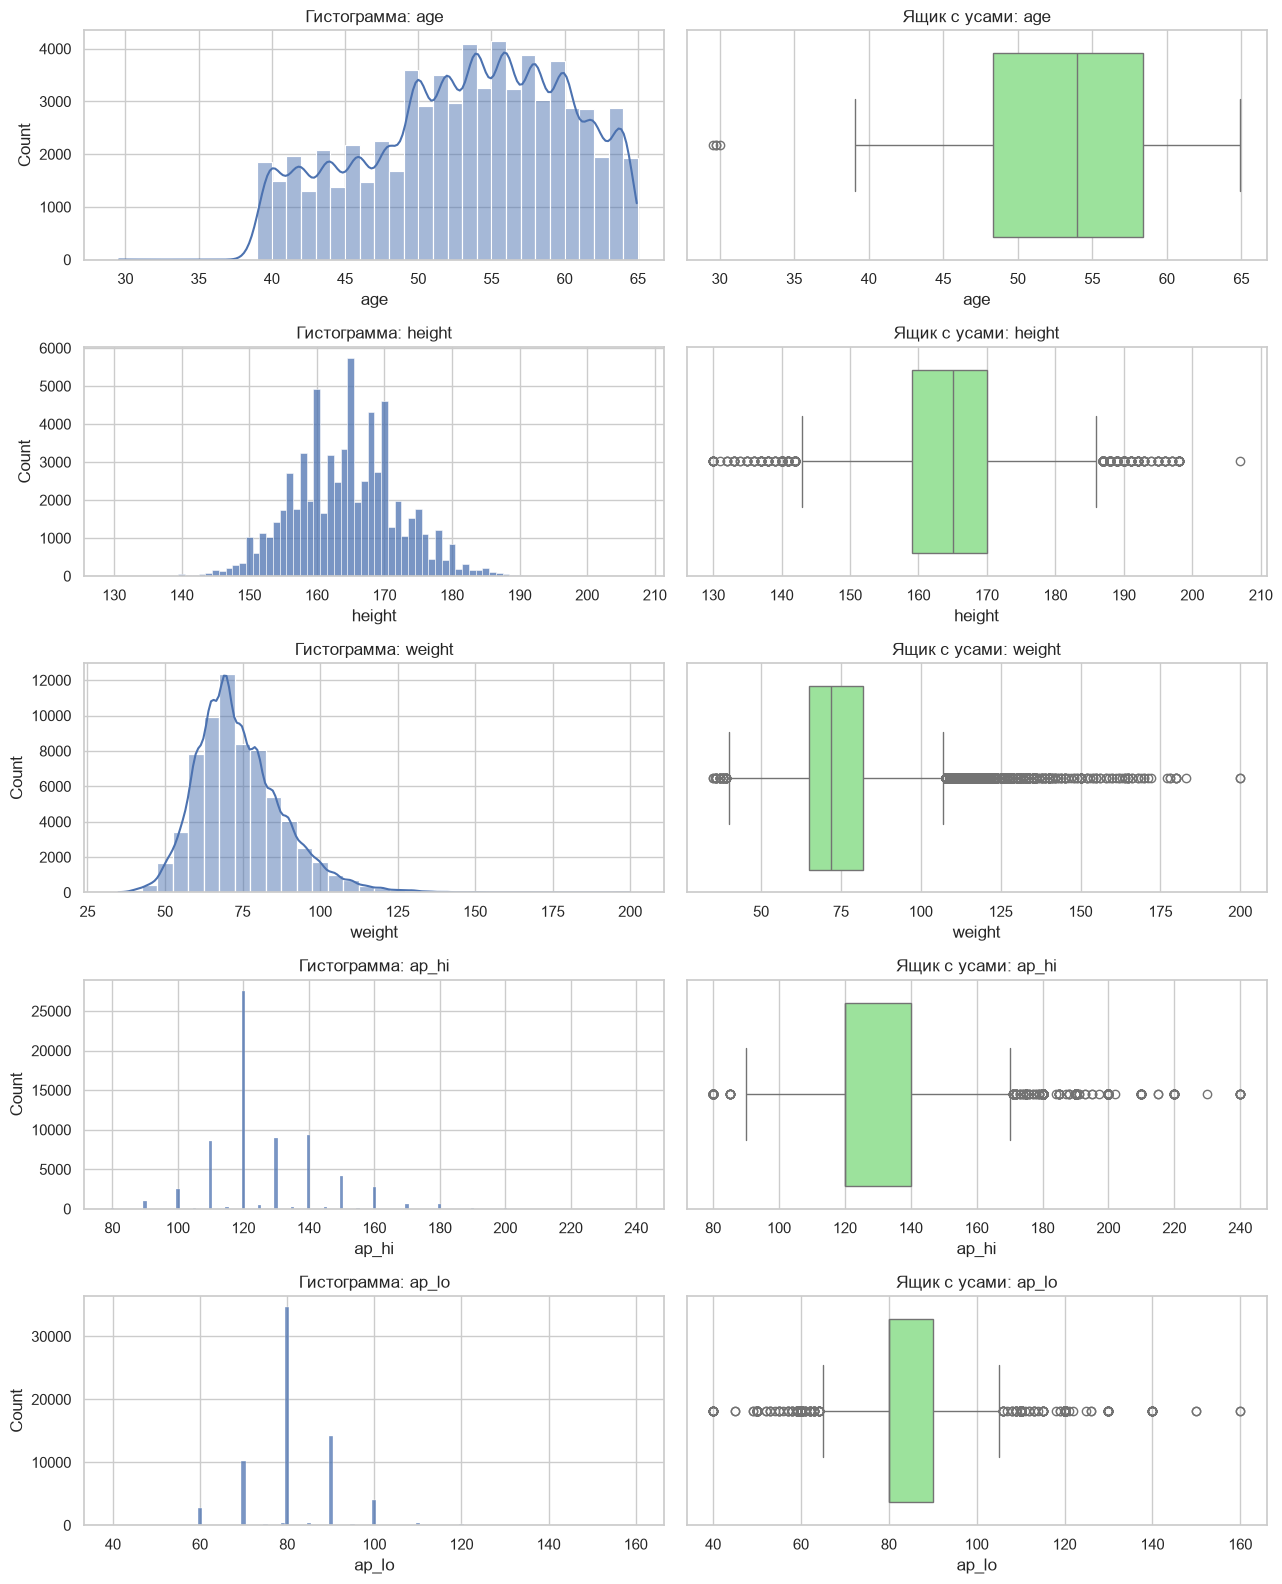

In [11]:
k = len(cont_cols)
fig, axes = plt.subplots(k, 2, figsize=(13, 3.2 * k), squeeze=False)
for i, c in enumerate(cont_cols):
    is_int = bool((df[c] == df[c].round()).all())   # целочисленные признаки — столбик на каждое значение
    if is_int:
        sns.histplot(df[c], discrete=True, ax=axes[i, 0])
    elif c == 'age':                                  # возраст — столбик на каждый полный год
        sns.histplot(df[c], bins=np.arange(np.floor(df[c].min()), np.ceil(df[c].max()) + 1), kde=True, ax=axes[i, 0])
    elif c == 'weight':                               # вес — шаг 5 кг с центрами на значениях, кратных 5
        sns.histplot(df[c], bins=np.arange(5 * np.floor(df[c].min() / 5) - 2.5, df[c].max() + 5, 5), kde=True, ax=axes[i, 0])
    else:
        sns.histplot(df[c], bins=40, kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f'Гистограмма: {c}')
    sns.boxplot(x=df[c], ax=axes[i, 1], color='lightgreen')
    axes[i, 1].set_title(f'Ящик с усами: {c}')
plt.tight_layout()
plt.show()

**Выводы о форме распределений и выбросах.**

- **age** — распределение асимметричное влево и «плоское»: почти все пациенты от 39 до 65 лет, после 50 лет их заметно больше. Соседние годы чередуются (нечётных возрастов больше), это особенность сбора данных. Выбросы — 4 пациента около 30 лет.
- **height** — одновершинное, почти симметричное, колоколообразное. Выбросы с обеих сторон (415 значений по правилу 1,5·IQR, 0,6%) — очень низкие и очень высокие люди. Пики на 150, 155, 160, 165, 170 см — рост округляли при записи. Распределение роста объединяет мужчин и женщин (см. п. 3.1).
- **weight** — асимметрия вправо (длинный правый хвост до 200 кг), 1 718 выбросов (2,5%), из них 1 687 справа: это реальные пациенты с большим весом, а не ошибки.
- **ap_hi**, **ap_lo** — распределения фактически дискретные: 97% значений кратны 10 мм рт. ст. (давление округляют при измерении), значение 120 у `ap_hi` встречается в 40% записей, 80 у `ap_lo` — в 51%. Правый хвост у `ap_hi` длиннее. У `ap_lo` по правилу IQR много «выбросов» (3 487, 5,1%): ящик очень узкий (80–90), поэтому за усы попадают обычные значения 60 (2 708 записей) и 110, это не ошибки.

Нормальным по форме выглядит только рост; возраст, вес и давление от нормального распределения заметно отличаются.

### 2.2. Матрица корреляций и диаграммы рассеяния

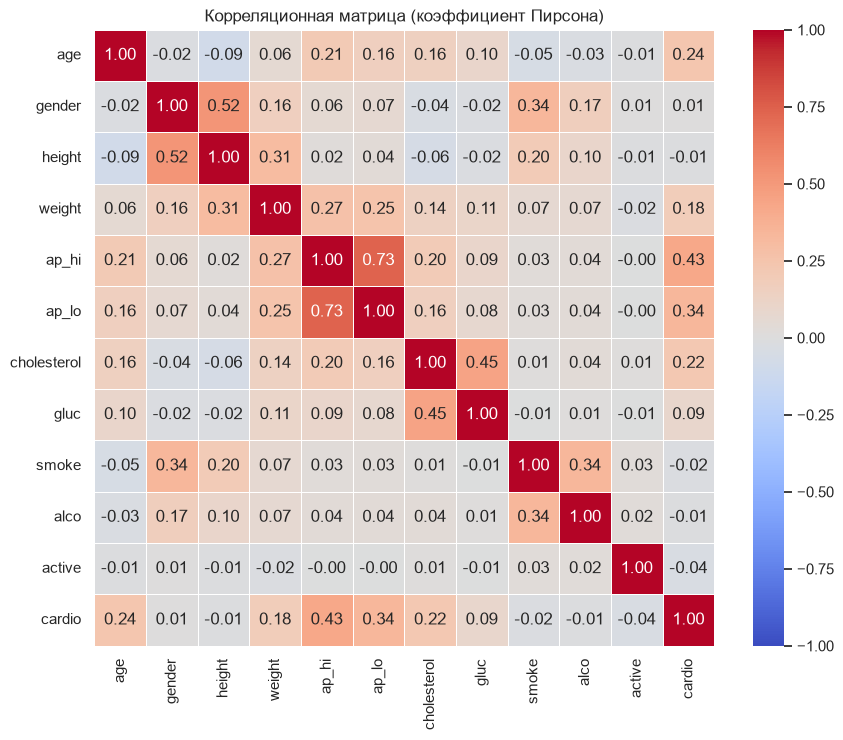

In [12]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Корреляционная матрица (коэффициент Пирсона)')
plt.show()

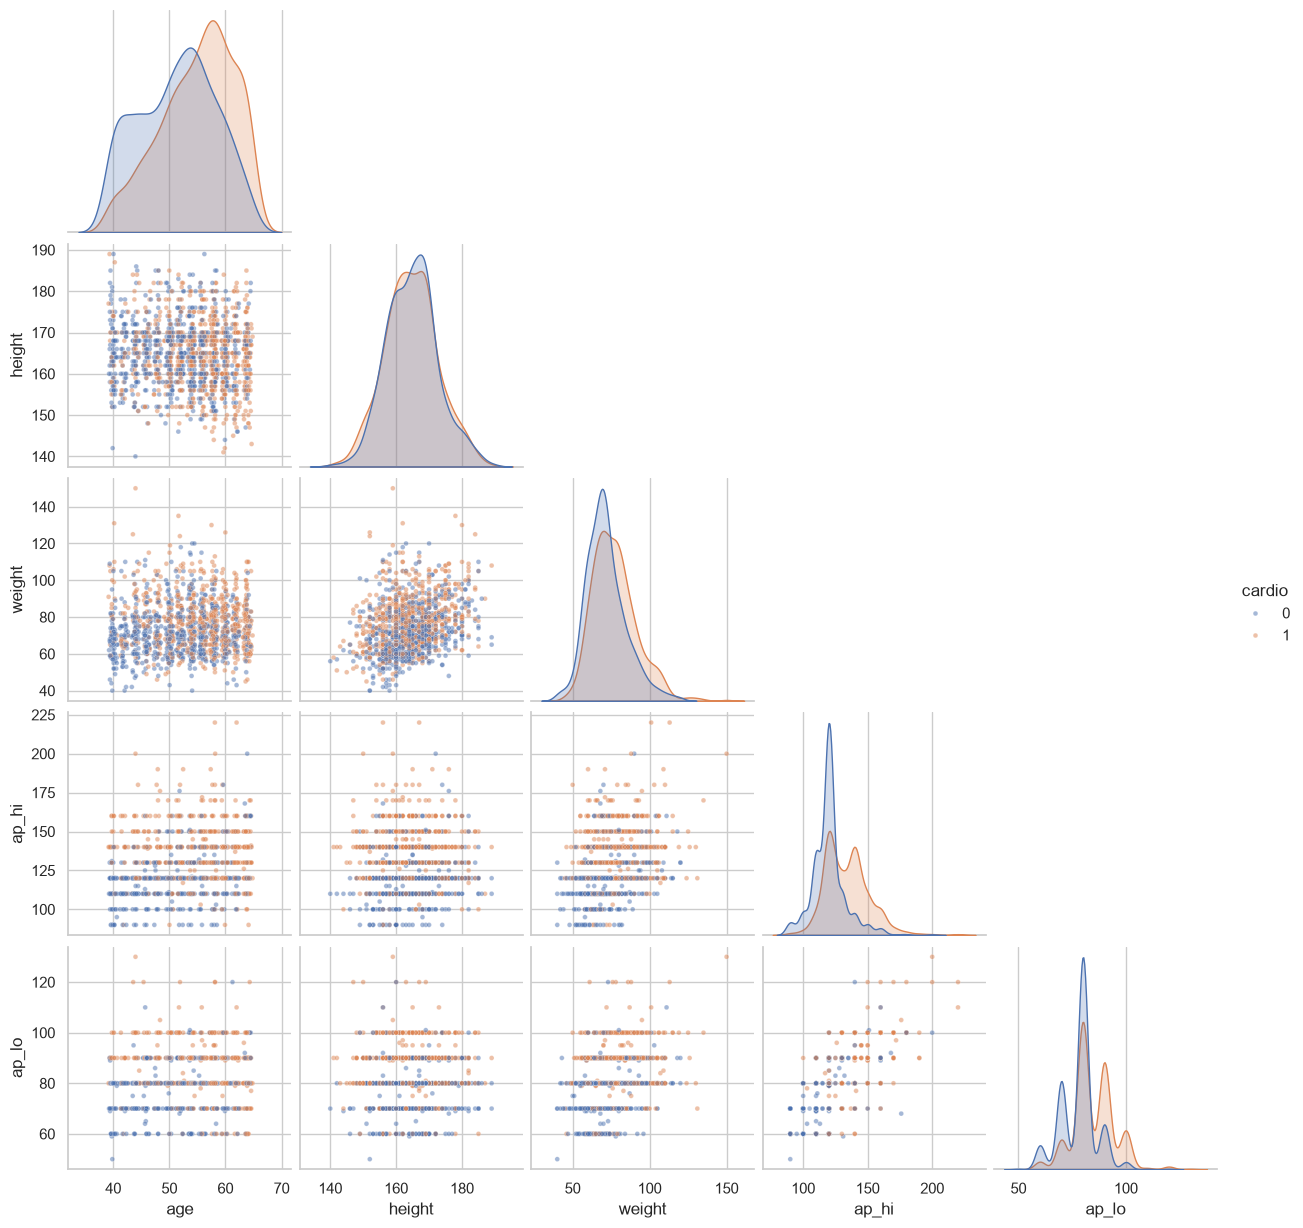

In [13]:
# Для читаемости — случайные 1500 пациентов
plot_df = df[cont_cols + [HUE_COL]].sample(1500, random_state=0)
sns.pairplot(plot_df, hue=HUE_COL, corner=True, plot_kws=dict(s=12, alpha=0.5))
plt.show()

### 2.3. Описательные статистики

In [14]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

desc = df[cont_cols].describe().T
desc.insert(2, 'median', df[cont_cols].median())
desc['skew'] = df[cont_cols].skew()                 # асимметрия
desc['kurt_excess'] = df[cont_cols].kurt()          # избыточный эксцесс (у нормального = 0)
desc['outliers_IQR'] = [iqr_outliers(df[c]) for c in cont_cols]
desc['outliers_%'] = desc['outliers_IQR'] / len(df) * 100
desc

,count,mean,median,std,min,25%,50%,75%,max,skew,kurt_excess,outliers_IQR,outliers_%
age,68535.0000,53.2929,53.9411,6.7571,29.5633,48.3450,53.9411,58.3847,64.9227,-0.3060,-0.8249,4,0.0058
height,68535.0000,164.4404,165.0000,7.8461,130.0000,159.0000,165.0000,170.0000,207.0000,0.1129,0.1916,415,0.6055
weight,68535.0000,74.1220,72.0000,14.2819,35.0000,65.0000,72.0000,82.0000,200.0000,0.9942,2.3940,1718,2.5067
ap_hi,68535.0000,126.6829,120.0000,16.6830,80.0000,120.0000,120.0000,140.0000,240.0000,0.9354,1.8353,1000,1.4591
ap_lo,68535.0000,81.3095,80.0000,9.4287,40.0000,80.0000,80.0000,90.0000,160.0000,0.3357,1.7007,3487,5.0879


In [15]:
# Доли значений категориальных и бинарных признаков
pd.DataFrame({c: df[c].value_counts(normalize=True) for c in cat_cols}).T.sort_index(axis=1)

,0,1,2,3
gender,NaN,0.6513,0.3487,NaN
cholesterol,NaN,0.7497,0.1356,0.1147
gluc,NaN,0.8502,0.0738,0.0760
smoke,0.9120,0.0880,NaN,NaN
alco,0.9466,0.0534,NaN,NaN
active,0.1966,0.8034,NaN,NaN
cardio,0.5052,0.4948,NaN,NaN


**Выводы.**

- У веса и систолического давления среднее больше медианы (74,1 против 72 кг; 126,7 против 120 мм рт. ст.), асимметрия около 1 — правый хвост. Положительный избыточный эксцесс (2,4 и 1,8) означает тяжёлые хвосты.
- У роста асимметрия 0,11 и эксцесс 0,19 — ближе всего к нормальному распределению; среднее и медиана почти совпадают (164,4 и 165 см).
- У возраста асимметрия −0,31 и отрицательный эксцесс −0,82 — распределение «плоское» и усечённое, не нормальное.
- Категориальные признаки: женщин 65,1%, мужчин 34,9%; у 75% пациентов холестерин в норме, у 85% — глюкоза; курят 8,8%, употребляют алкоголь 5,3%, физически активны 80,3%. Классы целевой переменной сбалансированы: 49,5% с заболеванием и 50,5% без.

### 2.4. Взаимосвязи признаков и мультиколлинеарность

In [16]:
corr = df.corr()
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = corr.where(mask).stack().dropna().rename('r').reset_index()
pairs.columns = ['признак 1', 'признак 2', 'r']
pairs['|r|'] = pairs['r'].abs()
display(pairs.sort_values('|r|', ascending=False).head(10).reset_index(drop=True))

# VIF без sklearn: диагональ обратной корреляционной матрицы признаков (без целевой переменной)
X_cols = [c for c in df.columns if c != 'cardio']
vif = pd.Series(np.diag(np.linalg.inv(df[X_cols].corr().values)), index=X_cols, name='VIF')
display(vif.sort_values(ascending=False).to_frame())

,признак 1,признак 2,r,|r|
0,ap_hi,ap_lo,0.7346,0.7346
1,gender,height,0.5218,0.5218
2,cholesterol,gluc,0.4506,0.4506
3,ap_hi,cardio,0.4281,0.4281
4,ap_lo,cardio,0.3405,0.3405
5,smoke,alco,0.3404,0.3404
6,gender,smoke,0.3389,0.3389
7,height,weight,0.3105,0.3105
8,weight,ap_hi,0.2705,0.2705
9,weight,ap_lo,0.2535,0.2535


,VIF
ap_hi,2.2750
ap_lo,2.1901
height,1.5164
gender,1.5068
cholesterol,1.3200
gluc,1.2597
smoke,1.2484
weight,1.2297
alco,1.1396
age,1.0736


**Выводы о взаимосвязях признаков.**

- Сильнее всего связаны систолическое и диастолическое давление (r = 0,73), что естественно. На диаграмме рассеяния видна решётка из-за округления давления до 10, но тренд линейный и возрастающий.
- Пол связан с ростом (r = 0,52; мужчины в среднем на 8,6 см выше) и с курением (0,34). Курение связано с алкоголем (0,34), холестерин — с глюкозой (0,45).
- Рост и вес связаны умеренно (0,31), вес и давление — слабо (0,25–0,27).
- Наличие заболевания `cardio` сильнее всего связано с давлением (0,43 и 0,34), затем с возрастом (0,24), холестерином (0,22) и весом (0,18). На pairplot это видно как сдвиг оранжевых точек (`cardio = 1`) в сторону большего давления и возраста. С курением, алкоголем и активностью связи практически нет (|r| ≤ 0,04) — возможно, из-за того, что эти признаки указывались самими пациентами.
- Остальные связи слабые (|r| < 0,25), заметных нелинейных зависимостей на диаграммах рассеяния нет.

**Мультиколлинеарность.** Максимальный VIF — у давления: 2,28 (`ap_hi`) и 2,19 (`ap_lo`), у остальных признаков он не больше 1,52. Это существенно ниже порога 5–10, и ни одна пара не имеет |r| > 0,8, поэтому сильной мультиколлинеарности нет. Умеренная коллинеарность пары `ap_hi`–`ap_lo` может проявиться в линейных моделях: при необходимости одну из переменных можно заменить, например, пульсовым давлением `ap_hi − ap_lo`.

## 3. Оценка параметров нормального распределения методом ММП
### 3.1. Выбор признака

,count,mean,std,skew
gender,,,,
1,44637,161.4449,6.6699,0.0378
2,23898,170.0353,6.7373,-0.0149


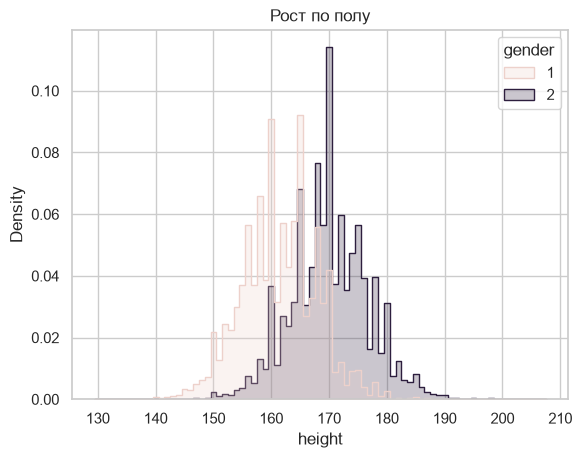

In [17]:
display(df.groupby('gender')[NORMAL_COL].agg(['count', 'mean', 'std', 'skew']))
sns.histplot(data=df, x=NORMAL_COL, hue='gender', discrete=True, stat='density',
             common_norm=False, element='step')
plt.title('Рост по полу')
plt.show()

**Обоснование выбора.** Для ММП выбран рост, так как это единственный количественный признак с симметричной колоколообразной формой (п. 2.1–2.3). Возраст усечён и «плоский», вес скошен вправо, давление дискретно.

Однако рост в целом — смесь двух распределений: средний рост группы 1 равен 161,4 см, группы 2 — 170,0 см (разница 8,6 см, это 1,3 стандартного отклонения). Поэтому по среднему росту группа 1 — женщины, группа 2 — мужчины. Внутри каждой группы распределение близко к нормальному и симметрично (асимметрия 0,04 и −0,01), разброс почти одинаковый (6,67 и 6,74 см). Для оценки параметров берём рост женщин — это бо́льшая группа: n = 44 637.

n = 44637, асимметрия = 0.038, избыточный эксцесс = 0.555
Доля значений, оканчивающихся на 0 или 5: 30.1% (без округления ≈ 20%)
Шапиро–Уилк (5000 случайных наблюдений): W = 0.9922, p = 5.93e-16
Д'Агостино–Пирсон:  K² = 368.4, p = 9.9e-81
Колмогоров–Смирнов: D = 0.0533, p = 9.25e-111  (параметры оценены по данным, p завышено)


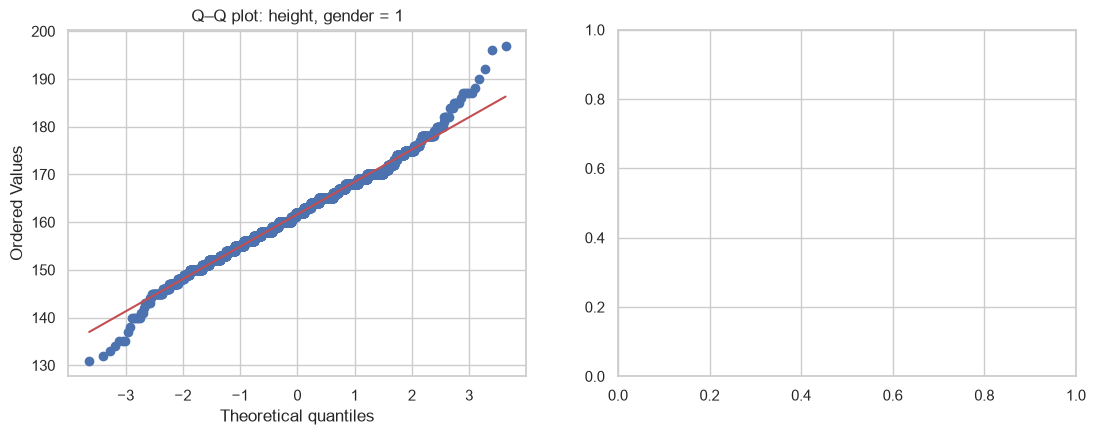

In [34]:
x = df.loc[df['gender'] == GENDER, NORMAL_COL].to_numpy(dtype=float)
n = len(x)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
# Q–Q plot по случайным 5000 точкам: вид графика тот же, а рисуется быстрее
x_plot = rng.choice(x, 5000, replace=False) if n > 5000 else x
stats.probplot(x_plot, dist='norm', plot=axes[0])
axes[0].set_title(f'Q–Q plot: {NORMAL_COL}, gender = {GENDER}')


print(f'n = {n}, асимметрия = {stats.skew(x):.3f}, избыточный эксцесс = {stats.kurtosis(x):.3f}')
print(f'Доля значений, оканчивающихся на 0 или 5: {np.mean(x % 5 == 0):.1%} (без округления ≈ 20%)')
sw = stats.shapiro(rng.choice(x, 5000, replace=False) if n > 5000 else x)
print(f'Шапиро–Уилк (5000 случайных наблюдений): W = {sw.statistic:.4f}, p = {sw.pvalue:.3g}')
dp = stats.normaltest(x)
print(f"Д'Агостино–Пирсон:  K² = {dp.statistic:.1f}, p = {dp.pvalue:.3g}")
ks = stats.kstest(x, stats.norm(loc=x.mean(), scale=x.std()).cdf)
print(f'Колмогоров–Смирнов: D = {ks.statistic:.4f}, p = {ks.pvalue:.3g}  (параметры оценены по данным, p завышено)')

**Вывод о нормальности.** Асимметрия 0,04 и избыточный эксцесс 0,56 близки к нулю, точки Q–Q plot лежат на прямой в диапазоне примерно ±2,5 стандартного отклонения. Отклонения есть только в хвостах: крайние значения встречаются немного чаще, чем у нормального распределения (отсюда положительный эксцесс).

Все три теста отвергают нормальность (p ≪ 0,05). Причины две. Первая — очень большая выборка: на десятках тысяч наблюдений тесты замечают даже практически несущественные отклонения. Вторая — округление при записи: на значения, оканчивающиеся на 0 и 5, приходится 30,1% наблюдений вместо ожидаемых ≈ 20%; цифры 0, 5 и 8 встречаются в 13–16% случаев, а 1 — только в 5%. Из-за этого распределение дискретно и «зубчато», что тесты воспринимают как отклонение от нормального закона.

Итог: рост женщин можно считать приближённо нормально распределённым, модель $N(\mu, \sigma^2)$ подходит для оценки параметров.

### 3.2. Функция логарифмического правдоподобия

$$\ell(\mu, \sigma) = -\frac n2 \ln 2\pi - n\ln\sigma - \frac{1}{2\sigma^2}\sum_{i=1}^n (x_i-\mu)^2$$

Это та же формула, что в методических указаниях ($-\frac n2\ln\sigma^2 = -n\ln\sigma$). От примера кода в п. 3.5 методических указаний реализация отличается в двух местах. Объём выборки берётся из самих данных (`len(data)`), а не из глобальной переменной `n`: иначе функция давала бы неверный результат на выборках другого объёма. Начальное приближение для оптимизации выбрано далеко от ответа, а не равным выборочным среднему и стандартному отклонению, — так видно, что оптимизатор действительно находит максимум.

In [19]:
def log_likelihood(params, data):
    mu, sigma = params
    m = len(data)                      # объём выборки берём из самих данных
    if sigma <= 0:
        return -np.inf
    return -m / 2 * np.log(2 * np.pi) - m * np.log(sigma) - np.sum((data - mu) ** 2) / (2 * sigma ** 2)

def neg_log_likelihood(params, data):
    return -log_likelihood(params, data)

### 3.3. Численная оптимизация и сравнение с выборочными характеристиками

In [20]:
# Начальное приближение специально далеко от ответа
init = [np.median(x) + x.std(), 2 * x.std()]
res = opt.minimize(neg_log_likelihood, init, args=(x,), method='L-BFGS-B',
                   bounds=[(None, None), (1e-6, None)])
mu_mle, sigma_mle = res.x
print(res.message, '| итераций:', res.nit)
print(f'Старт: μ = {init[0]:.3f}, σ = {init[1]:.3f}')
print(f'ММП (scipy.optimize.minimize): μ̂ = {mu_mle:.6f}, σ̂ = {sigma_mle:.6f}, log L = {-res.fun:.3f}')

CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH | итераций: 8
Старт: μ = 168.670, σ = 13.340
ММП (scipy.optimize.minimize): μ̂ = 161.444944, σ̂ = 6.669839, log L = -148040.125


In [21]:
mu_fit, sigma_fit = stats.norm.fit(x)
comp = pd.DataFrame({
    'μ': [mu_mle, x.mean(), x.mean(), mu_fit],
    'σ': [sigma_mle, x.std(ddof=0), x.std(ddof=1), sigma_fit],
}, index=['ММП: scipy.optimize.minimize',
          'выборочные, деление на n (ddof=0)',
          'выборочные, деление на n−1 (ddof=1)',
          'scipy.stats.norm.fit'])
comp['σ − σ̂(ММП)'] = comp['σ'] - sigma_mle
comp.style.format('{:.6f}').format('{:+.1e}', subset=['σ − σ̂(ММП)'])

,μ,σ,σ − σ̂(ММП)
ММП: scipy.optimize.minimize,161.444944,6.669839,+0.0e+00
"выборочные, деление на n (ddof=0)",161.444922,6.669837,-1.8e-06
"выборочные, деление на n−1 (ddof=1)",161.444922,6.669911,+7.3e-05
scipy.stats.norm.fit,161.444922,6.669837,-1.8e-06


**Вывод.** Численная оптимизация из заведомо далёкой стартовой точки (μ = 168,7, σ = 13,3) сошлась за 8 итераций к μ̂ = 161,4449 см и σ̂ = 6,6698 см.

- Оценки совпадают с выборочным средним и стандартным отклонением с делением на n: расхождение 2·10⁻⁵ для μ и 3·10⁻⁷ для σ — это погрешность численного метода. `scipy.stats.norm.fit` даёт то же самое. Это подтверждает теорию: оценка σ по ММП — стандартное отклонение с делением на n.
- Стандартное отклонение с делением на n−1 больше на 7,4·10⁻⁵ (в $\sqrt{n/(n-1)}$ раз). При n = 44 637 эта разница в 300 раз меньше стандартной ошибки самой оценки (≈ 0,022), то есть практического значения не имеет.

### 3.4. Плотность нормального распределения с оценками ММП на гистограмме данных

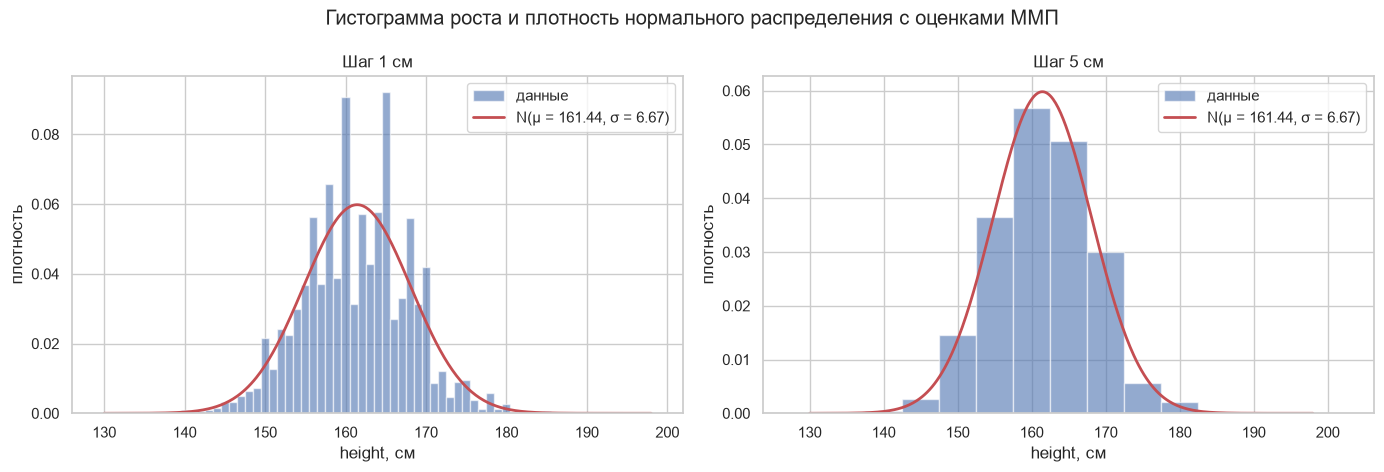

In [22]:
grid = np.linspace(x.min(), x.max(), 400)
pdf = stats.norm.pdf(grid, mu_mle, sigma_mle)
label = f'N(μ = {mu_mle:.2f}, σ = {sigma_mle:.2f})'

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
# Слева: столбик на каждый сантиметр — видно округление при записи
axes[0].hist(x, bins=np.arange(x.min() - 0.5, x.max() + 1.5, 1), density=True, alpha=0.6, label='данные')
axes[0].set_title('Шаг 1 см')
# Справа: шаг 5 см с центрами на значениях, кратных 5, — округление сглаживается
edges = np.arange(5 * np.floor(x.min() / 5) - 2.5, x.max() + 5, 5)
axes[1].hist(x, bins=edges, density=True, alpha=0.6, label='данные')
axes[1].set_title('Шаг 5 см')
for ax in axes:
    ax.plot(grid, pdf, 'r', lw=2, label=label)
    ax.set_xlabel(f'{NORMAL_COL}, см'); ax.set_ylabel('плотность'); ax.legend()
plt.suptitle('Гистограмма роста и плотность нормального распределения с оценками ММП')
plt.tight_layout(); plt.show()

**Вывод.** Нормальная плотность с оценками ММП хорошо повторяет общую форму распределения: положение, ширину и симметрию. На гистограмме с шагом 1 см видны пики на округлённых значениях (150, 155, 160, 165, 170 см) и провалы рядом с ними — это следствие округления, а не формы распределения. На гистограмме с шагом 5 см, где эффект округления сглажен, данные почти совпадают с кривой; заметны лишь небольшой избыток в центре и чуть более тяжёлые хвосты (эксцесс 0,56).

## 4. Имитационное исследование свойств оценок ММП

«Истинные» параметры для симуляций — оценки ММП по исходным данным: $\mu = \hat\mu$, $\sigma = \hat\sigma$.

Информация Фишера для одного наблюдения (методические указания, п. 3.4): $I(\mu) = 1/\sigma^2$, $I(\sigma^2) = 1/(2\sigma^4)$. Для выборки объёма n она умножается на n, откуда граница Крамера–Рао: $D\hat\mu \ge \sigma^2/n$, $D\hat\sigma^2 \ge 2\sigma^4/n$. Оценки ММП асимптотически достигают этой границы (эффективность). Теоретические предсказания:

- $\hat\mu \sim N(\mu,\ \sigma^2/n)$, $E\hat\mu = \mu$ (несмещённая);
- $\hat\sigma^2_{ММП}$: $E\hat\sigma^2 = \frac{n-1}{n}\sigma^2$, смещение $-\sigma^2/n$; асимптотическая дисперсия $2\sigma^4/n$;
- $\hat\sigma$: асимптотическая дисперсия $\sigma^2/(2n)$ (дельта-метод из $2\sigma^4/n$).

### 4.1. 500 симуляций выборок того же объёма

Для нормального распределения максимум функции правдоподобия находится аналитически: $\hat\mu = \bar x$, $\hat\sigma^2 = \frac1n\sum(x_i-\bar x)^2$. В п. 3.3 показано, что численная оптимизация даёт тот же результат, поэтому в симуляциях оценки ММП вычисляются по этим формулам (как в методических указаниях, п. 3.6). Для контроля на 20 выборках оценки дополнительно найдены через `scipy.optimize.minimize`.

In [23]:
true_mu, true_sigma = mu_mle, sigma_mle

mu_hats = np.empty(N_SIM)
sigma_hats = np.empty(N_SIM)
for i in range(N_SIM):
    sample = rng.normal(true_mu, true_sigma, size=n)    # выборка того же объёма
    mu_hats[i] = sample.mean()                          # ММП-оценка μ
    sigma_hats[i] = sample.std(ddof=0)                  # ММП-оценка σ (деление на n)

# Контроль: численная оптимизация на 20 выборках
diffs = []
for _ in range(20):
    sample = rng.normal(true_mu, true_sigma, size=n)
    r = opt.minimize(neg_log_likelihood, [np.median(sample), 2 * sample.std()], args=(sample,),
                     method='L-BFGS-B', bounds=[(None, None), (1e-6, None)])
    diffs.append(np.abs(r.x - [sample.mean(), sample.std()]).max())
print(f'Выполнено симуляций: {N_SIM}, объём каждой выборки n = {n}')
print(f'Макс. расхождение minimize и формул на 20 выборках: {max(diffs):.1e}'
      f' (стандартная ошибка μ̂ ≈ {true_sigma / np.sqrt(n):.3f})')

Выполнено симуляций: 500, объём каждой выборки n = 44637
Макс. расхождение minimize и формул на 20 выборках: 2.9e-04 (стандартная ошибка μ̂ ≈ 0.032)


### 4.2. Гистограммы распределений оценок μ̂ и σ̂ с истинными значениями параметров

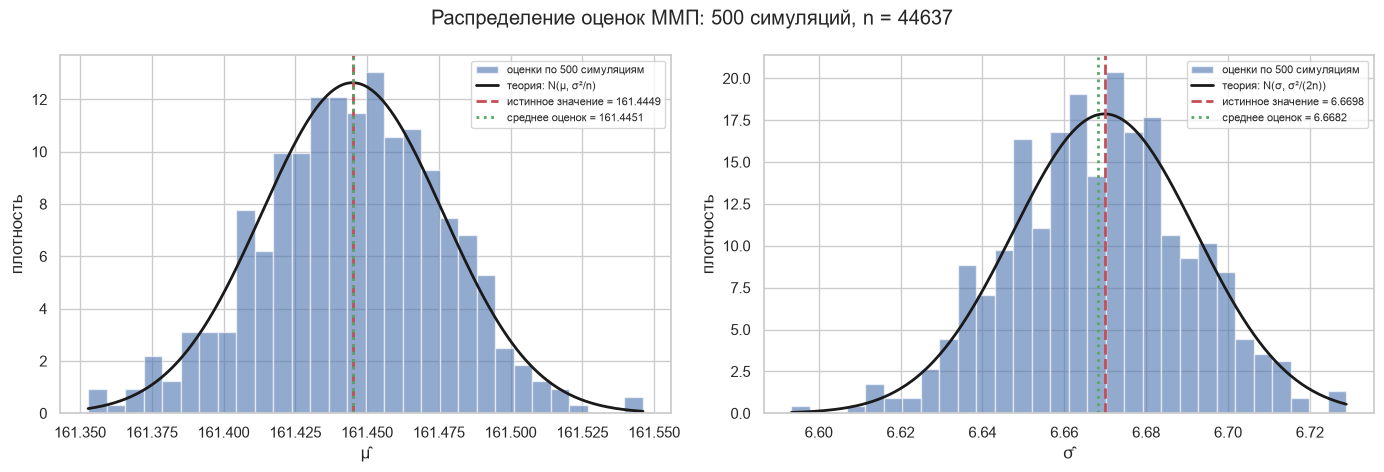

In [24]:
se_mu = true_sigma / np.sqrt(n)
se_sigma = true_sigma / np.sqrt(2 * n)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
panels = [(axes[0], mu_hats, true_mu, se_mu, 'μ̂', 'теория: N(μ, σ²/n)'),
          (axes[1], sigma_hats, true_sigma, se_sigma, 'σ̂', 'теория: N(σ, σ²/(2n))')]
for ax, est, true, se, name, th_label in panels:
    ax.hist(est, bins=30, density=True, alpha=0.6, label='оценки по 500 симуляциям')
    g = np.linspace(est.min(), est.max(), 300)
    ax.plot(g, stats.norm.pdf(g, true, se), 'k', lw=2, label=th_label)
    ax.axvline(true, color='r', ls='--', lw=2, label=f'истинное значение = {true:.4f}')
    ax.axvline(est.mean(), color='g', ls=':', lw=2, label=f'среднее оценок = {est.mean():.4f}')
    ax.set_xlabel(name); ax.set_ylabel('плотность'); ax.legend(fontsize=8)
plt.suptitle(f'Распределение оценок ММП: {N_SIM} симуляций, n = {n}')
plt.tight_layout(); plt.show()

### 4.3. Проверка несмещённости

In [25]:
# Точное матожидание σ̂ (деление на n) для нормальной выборки
e_sigma = true_sigma * np.sqrt(2 / n) * np.exp(gammaln(n / 2) - gammaln((n - 1) / 2))

unbias = pd.DataFrame({
    'истинное':          [true_mu, true_sigma, true_sigma ** 2],
    'среднее оценок':    [mu_hats.mean(), sigma_hats.mean(), (sigma_hats ** 2).mean()],
    'теор. E[оценки]':   [true_mu, e_sigma, (n - 1) / n * true_sigma ** 2],
    'SD оценок (эмп.)':  [mu_hats.std(ddof=1), sigma_hats.std(ddof=1), (sigma_hats ** 2).std(ddof=1)],
    'SD (теория)':       [se_mu, se_sigma, np.sqrt(2 / n) * true_sigma ** 2],
}, index=['μ̂', 'σ̂', 'σ̂² (ММП)'])
unbias['смещение (эмп.)'] = unbias['среднее оценок'] - unbias['истинное']
unbias['погрешность МК'] = unbias['SD оценок (эмп.)'] / np.sqrt(N_SIM)   # стандартная ошибка среднего 500 оценок
unbias['смещение / погр. МК'] = unbias['смещение (эмп.)'] / unbias['погрешность МК']
unbias

,истинное,среднее оценок,теор. E[оценки],SD оценок (эмп.),SD (теория),смещение (эмп.),погрешность МК,смещение / погр. МК
μ̂,161.4449,161.4451,161.4449,0.0320,0.0316,0.0002,0.0014,0.1072
σ̂,6.6698,6.6682,6.6697,0.0218,0.0223,-0.0016,0.0010,-1.6293
σ̂² (ММП),44.4867,44.4660,44.4857,0.2911,0.2978,-0.0207,0.0130,-1.5932


Как читать таблицу: «погрешность МК» — стандартная ошибка среднего по 500 симуляциям. Если |смещение / погр. МК| < 2, отличие среднего оценок от истинного значения объясняется случайностью симуляций, и смещение не обнаруживается. Теоретическое смещение $\hat\sigma^2$ равно $-\sigma^2/n$, при большом n оно очень мало, поэтому дополнительно смотрим на малые выборки в п. 4.4.

### 4.4. Проверка состоятельности: объём выборки от 10 до 500

,SD μ̂,теория σ/√n,SD σ̂,теория σ/√(2n),смещение σ̂² (÷n),теория −σ²/n,смещение s² (÷(n−1))
n,,,,,,,
10,2.2565,2.1092,1.4903,1.4914,-5.2466,-4.4487,-0.8865
20,1.4550,1.4914,1.0315,1.0546,-2.0010,-2.2243,0.2351
30,1.2875,1.2177,0.8581,0.8611,-1.0351,-1.4829,0.4633
50,0.9677,0.9433,0.6833,0.6670,-0.8627,-0.8897,0.0276
75,0.7536,0.7702,0.5271,0.5446,-0.5661,-0.5932,0.0275
100,0.6316,0.6670,0.4789,0.4716,-0.4580,-0.4449,-0.0133
150,0.5449,0.5446,0.3709,0.3851,0.0599,-0.2966,0.3588
200,0.4813,0.4716,0.3222,0.3335,-0.0635,-0.2224,0.1597
300,0.4014,0.3851,0.2624,0.2723,-0.4964,-0.1483,-0.3493


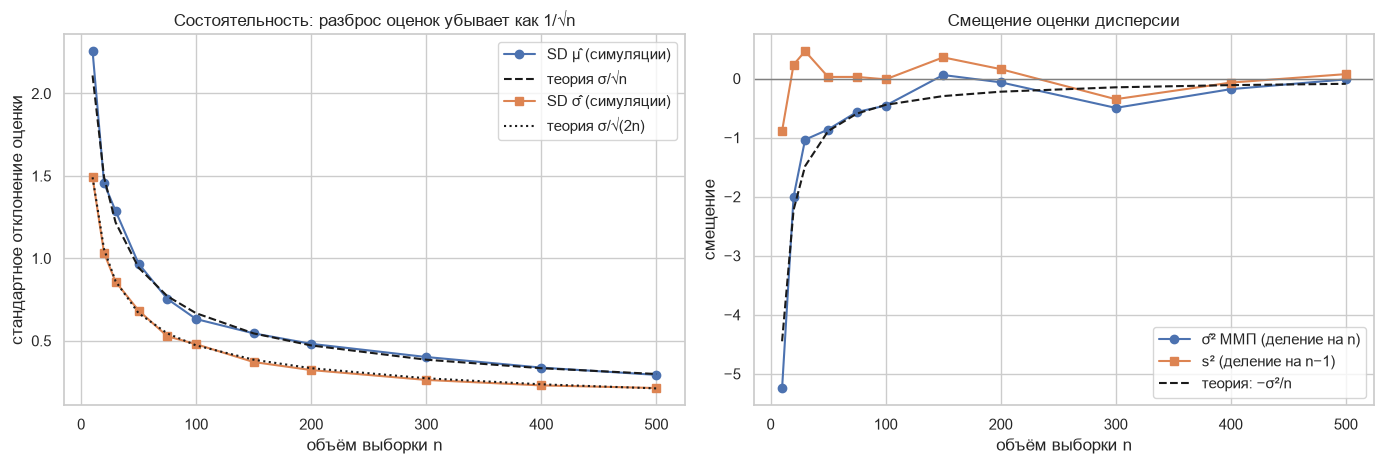

In [26]:
ns = [10, 20, 30, 50, 75, 100, 150, 200, 300, 400, 500]
rows = []
for m in ns:
    samples = rng.normal(true_mu, true_sigma, size=(N_SIM, m))
    mu_h = samples.mean(axis=1)
    sig_h = samples.std(axis=1, ddof=0)
    rows.append({'n': m,
                 'SD μ̂': mu_h.std(ddof=1),
                 'теория σ/√n': true_sigma / np.sqrt(m),
                 'SD σ̂': sig_h.std(ddof=1),
                 'теория σ/√(2n)': true_sigma / np.sqrt(2 * m),
                 'смещение σ̂² (÷n)': (sig_h ** 2).mean() - true_sigma ** 2,
                 'теория −σ²/n': -true_sigma ** 2 / m,
                 'смещение s² (÷(n−1))': samples.var(axis=1, ddof=1).mean() - true_sigma ** 2})
cons = pd.DataFrame(rows).set_index('n')
display(cons)

nn = np.array(ns)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(nn, cons['SD μ̂'], 'o-', label='SD μ̂ (симуляции)')
axes[0].plot(nn, true_sigma / np.sqrt(nn), 'k--', label='теория σ/√n')
axes[0].plot(nn, cons['SD σ̂'], 's-', label='SD σ̂ (симуляции)')
axes[0].plot(nn, true_sigma / np.sqrt(2 * nn), 'k:', label='теория σ/√(2n)')
axes[0].set_xlabel('объём выборки n'); axes[0].set_ylabel('стандартное отклонение оценки')
axes[0].set_title('Состоятельность: разброс оценок убывает как 1/√n'); axes[0].legend()

axes[1].plot(nn, cons['смещение σ̂² (÷n)'], 'o-', label='σ̂² ММП (деление на n)')
axes[1].plot(nn, cons['смещение s² (÷(n−1))'], 's-', label='s² (деление на n−1)')
axes[1].plot(nn, -true_sigma ** 2 / nn, 'k--', label='теория: −σ²/n')
axes[1].axhline(0, color='gray', lw=1)
axes[1].set_xlabel('объём выборки n'); axes[1].set_ylabel('смещение')
axes[1].set_title('Смещение оценки дисперсии'); axes[1].legend()
plt.tight_layout(); plt.show()

### 4.5. Асимптотическая нормальность оценок

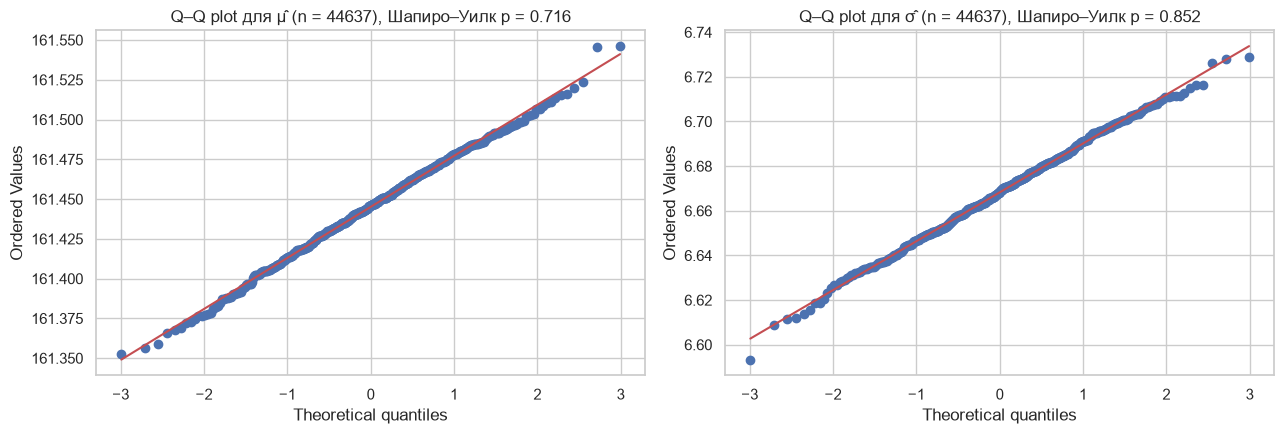

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, est, name in [(axes[0], mu_hats, 'μ̂'), (axes[1], sigma_hats, 'σ̂')]:
    stats.probplot(est, dist='norm', plot=ax)
    ax.set_title(f'Q–Q plot для {name} (n = {n}), Шапиро–Уилк p = {stats.shapiro(est).pvalue:.3f}')
plt.tight_layout(); plt.show()

**Выводы по имитационному исследованию.**

**Несмещённость (п. 4.3).** Среднее 500 оценок μ̂ равно 161,4451 при истинном 161,4449: смещение 0,0002 составляет всего 0,1 погрешности Монте-Карло, то есть смещения нет, как и предсказывает теория. Для σ̂ и σ̂² отклонения (−0,0016 и −0,021) тоже меньше двух погрешностей МК (1,6). Теоретическое смещение σ̂² при этом n равно −σ²/n ≈ −0,001 — оно более чем в 10 раз меньше погрешности симуляций, поэтому при n = 44 637 его не видно. На малых выборках (п. 4.4) смещение σ̂² хорошо заметно и совпадает с теорией: −5,2 при n = 10 (теория −4,4), −2,0 при n = 20 (теория −2,2), −0,9 при n = 50 (теория −0,9). Несмещённая оценка s² с делением на n−1 колеблется около нуля в пределах погрешности.

**Разброс оценок и эффективность.** Эмпирические стандартные отклонения совпадают с теоретическими: 0,0320 против σ/√n = 0,0316 для μ̂ и 0,0218 против σ/√(2n) = 0,0223 для σ̂ (различия 1–2%). Теоретические значения — это граница Крамера–Рао, вычисленная по информации Фишера: эмпирическая дисперсия μ̂ равна 1,02·10⁻³ при границе σ²/n = 1,00·10⁻³, дисперсия σ̂² — 0,085 при границе 2σ⁴/n = 0,089. Различия в пределах точности 500 симуляций (около 6%), то есть оценки ММП эффективны.

**Состоятельность (п. 4.4).** При росте n от 10 до 500 стандартное отклонение μ̂ уменьшилось с 2,26 до 0,29, σ̂ — с 1,49 до 0,21, то есть примерно в 7 раз при увеличении n в 50 раз ($\sqrt{50} \approx 7{,}1$). Эмпирические точки лежат на теоретических кривых σ/√n и σ/√(2n): дисперсия оценок стремится к нулю, оценки состоятельны.

**Асимптотическая нормальность (п. 4.2, 4.5).** Гистограммы μ̂ и σ̂ совпадают с теоретическими нормальными плотностями $N(\mu, \sigma^2/n)$ и $N(\sigma, \sigma^2/(2n))$, точки Q–Q plot лежат на прямой, тест Шапиро–Уилка нормальность не отвергает (p = 0,72 и 0,85).

## 5. Сравнение ММП с методом моментов и вторая модель без scipy.optimize

### 5.1. Нормальное распределение: аналитическое решение ММП и метод моментов

ММП: $\hat\mu = \frac1n\sum x_i$, $\hat\sigma^2 = \frac1n\sum (x_i-\hat\mu)^2$. Метод моментов: $\bar x = \mu$, $\frac1n\sum(x_i-\bar x)^2 = \sigma^2$ — те же формулы.

In [28]:
def normal_mle_manual(data):
    # Аналитическое решение ММП без numpy-статистик и без scipy.optimize
    total = 0.0
    for v in data:
        total += v
    m = len(data)
    mu = total / m
    ss = 0.0
    for v in data:
        ss += (v - mu) ** 2
    return mu, (ss / m) ** 0.5

def normal_mm(data):
    m1 = np.mean(data)                     # первый момент
    m2c = np.mean((data - m1) ** 2)        # второй центральный момент
    return m1, np.sqrt(m2c)

mu_man, sigma_man = normal_mle_manual(x)
mu_mm, sigma_mm = normal_mm(x)
pd.DataFrame({'μ': [mu_man, mu_mm, mu_mle], 'σ': [sigma_man, sigma_mm, sigma_mle]},
             index=['ММП аналитически (вручную)', 'метод моментов', 'ММП численно (minimize)']
            ).style.format('{:.6f}')

,μ,σ
ММП аналитически (вручную),161.444922,6.669837
метод моментов,161.444922,6.669837
ММП численно (minimize),161.444944,6.669839


**Вывод.** Для нормального распределения метод моментов и ММП дают одни и те же формулы, поэтому оценки совпадают до последнего знака: μ = 161,444922, σ = 6,669837. Аналитическое решение ММП, реализованное вручную, совпадает с результатом `scipy.optimize.minimize` с точностью 2·10⁻⁵. Для роста вопрос «какой метод точнее» не имеет смысла — оценки одинаковы. Содержательное сравнение возможно для распределения, где методы дают разные оценки, — гамма-распределения веса (п. 5.3–5.4).

### 5.2. Экспоненциальное распределение

$f(x;\lambda)=\lambda e^{-\lambda x},\ x>0$, $\quad \ell(\lambda) = n\ln\lambda - \lambda\sum x_i$.
Из $\ell'(\lambda) = n/\lambda - \sum x_i = 0$ следует $\hat\lambda = 1/\bar x$. Метод моментов ($EX = 1/\lambda$) даёт ту же оценку.

### 5.3. Гамма-распределение

$f(x;k,\theta)=\dfrac{x^{k-1}e^{-x/\theta}}{\Gamma(k)\theta^k}$, $\quad \ell = (k-1)\sum\ln x_i - \frac1\theta\sum x_i - n\ln\Gamma(k) - nk\ln\theta$.

- $\partial\ell/\partial\theta = 0 \Rightarrow \hat\theta = \bar x / k$;
- подстановка в $\partial\ell/\partial k = 0$ даёт $\ln k - \psi(k) = s$, где $s = \ln\bar x - \frac1n\sum\ln x_i$, $\psi$ — дигамма-функция.

Уравнение для $k$ решается методом Ньютона: $k \leftarrow k - \dfrac{\ln k - \psi(k) - s}{1/k - \psi'(k)}$, начальное приближение $k_0 = \dfrac{3 - s + \sqrt{(s-3)^2 + 24s}}{12s}$.

Метод моментов: $EX = k\theta$, $DX = k\theta^2$ $\Rightarrow$ $\hat k_{ММ} = \bar x^2 / s^2$, $\hat\theta_{ММ} = s^2 / \bar x$ — здесь оценки ММП и ММ различаются.

Применяем модели к весу (`weight`): признак положительный, с правым хвостом (п. 2.3).

In [29]:
y = df[SKEWED_COL].to_numpy(dtype=float)
ny = len(y)

def exp_mle_manual(data):
    return len(data) / sum(data)                       # λ̂ = 1 / x̄

def gamma_mle_newton(data, tol=1e-12, max_iter=100):
    data = np.asarray(data, dtype=float)
    mean = data.mean()
    s = np.log(mean) - np.mean(np.log(data))
    k = (3 - s + np.sqrt((s - 3) ** 2 + 24 * s)) / (12 * s)
    for it in range(1, max_iter + 1):
        f = np.log(k) - digamma(k) - s
        fprime = 1 / k - polygamma(1, k)
        k_new = k - f / fprime
        if k_new <= 0:
            k_new = k / 2
        converged = abs(k_new - k) < tol * k
        k = k_new
        if converged:
            break
    return k, mean / k, it

def gamma_mm(data):
    m, v = np.mean(data), np.var(data)
    return m ** 2 / v, v / m

lam_hat = exp_mle_manual(y)
k_mle, theta_mle, iters = gamma_mle_newton(y)
k_mm, theta_mm = gamma_mm(y)
print(f'n = {ny}')
print(f'Экспоненциальное, ММП вручную:   λ̂ = {lam_hat:.6f} (1/λ̂ = {1 / lam_hat:.4f})')
print(f'Гамма, ММП вручную (Ньютон, {iters} итер.): k̂ = {k_mle:.5f}, θ̂ = {theta_mle:.5f}')
print(f'Гамма, метод моментов:            k̂ = {k_mm:.5f}, θ̂ = {theta_mm:.5f}')

n = 68535
Экспоненциальное, ММП вручную:   λ̂ = 0.013491 (1/λ̂ = 74.1220)
Гамма, ММП вручную (Ньютон, 3 итер.): k̂ = 28.69093, θ̂ = 2.58346
Гамма, метод моментов:            k̂ = 26.93570, θ̂ = 2.75181


In [30]:
# Сравнение ручных формул с численной оптимизацией и встроенными функциями
def gamma_nll(log_params, data):
    k, theta = np.exp(log_params)          # оптимизируем логарифмы, чтобы k, θ > 0
    return -np.sum(stats.gamma.logpdf(data, a=k, scale=theta))

def exp_nll(log_lam, data):
    lam = np.exp(log_lam[0])
    return -(len(data) * np.log(lam) - lam * np.sum(data))

r_g = opt.minimize(gamma_nll, x0=np.log([1.0, y.mean()]), args=(y,), method='L-BFGS-B')
r_e = opt.minimize(exp_nll, x0=[np.log(1 / np.median(y))], args=(y,), method='L-BFGS-B')
a_fit, _, scale_fit = stats.gamma.fit(y, floc=0)
_, exp_scale_fit = stats.expon.fit(y, floc=0)

def ll_gamma(k, th):
    return np.sum(stats.gamma.logpdf(y, a=k, scale=th))

table = pd.DataFrame([
    ['Экспоненц., ММП вручную',     1.0,   1 / lam_hat,          ll_gamma(1, 1 / lam_hat), 1],
    ['Экспоненц., scipy.optimize',  1.0,   1 / np.exp(r_e.x[0]), ll_gamma(1, 1 / np.exp(r_e.x[0])), 1],
    ['Экспоненц., stats.expon.fit', 1.0,   exp_scale_fit,        ll_gamma(1, exp_scale_fit), 1],
    ['Гамма, ММП вручную (Ньютон)', k_mle, theta_mle,            ll_gamma(k_mle, theta_mle), 2],
    ['Гамма, scipy.optimize',       *np.exp(r_g.x),              -r_g.fun, 2],
    ['Гамма, stats.gamma.fit',      a_fit, scale_fit,            ll_gamma(a_fit, scale_fit), 2],
    ['Гамма, метод моментов',       k_mm,  theta_mm,             ll_gamma(k_mm, theta_mm), 2],
], columns=['модель / метод', 'k (форма)', 'θ (масштаб)', 'log L', 'параметров']).set_index('модель / метод')
table['AIC'] = 2 * table['параметров'] - 2 * table['log L']
table

,k (форма),θ (масштаб),log L,параметров,AIC
модель / метод,,,,,
"Экспоненц., ММП вручную",1.0000,74.1220,-363626.9528,1,727255.9056
"Экспоненц., scipy.optimize",1.0000,74.1219,-363626.9528,1,727255.9056
"Экспоненц., stats.expon.fit",1.0000,74.1220,-363626.9528,1,727255.9056
"Гамма, ММП вручную (Ньютон)",28.6909,2.5835,-276514.0523,2,553032.1046
"Гамма, scipy.optimize",28.6909,2.5835,-276514.0523,2,553032.1046
"Гамма, stats.gamma.fit",28.6909,2.5835,-276514.0523,2,553032.1046
"Гамма, метод моментов",26.9357,2.7518,-276581.7125,2,553167.4250


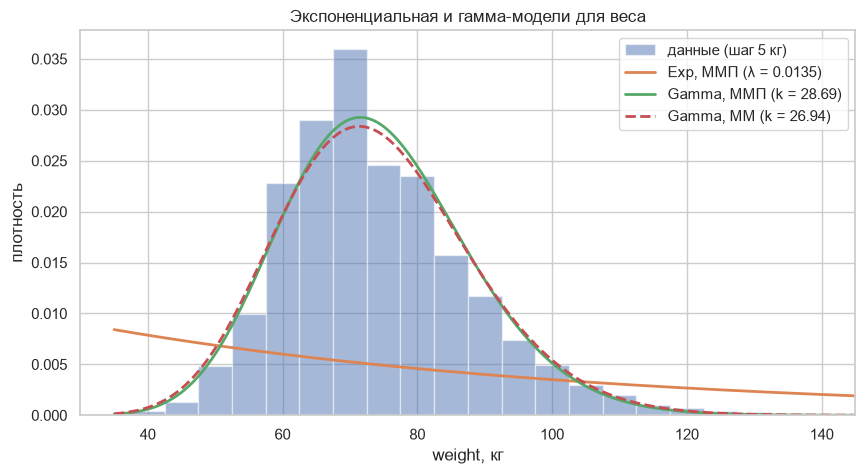

In [31]:
g = np.linspace(y.min(), np.quantile(y, 0.999), 400)
plt.figure(figsize=(10, 5))
plt.hist(y, bins=np.arange(5 * np.floor(y.min() / 5) - 2.5, y.max() + 5, 5), density=True, alpha=0.5, label='данные (шаг 5 кг)')
plt.plot(g, stats.expon.pdf(g, scale=1 / lam_hat), lw=2, label=f'Exp, ММП (λ = {lam_hat:.4f})')
plt.plot(g, stats.gamma.pdf(g, a=k_mle, scale=theta_mle), lw=2, label=f'Gamma, ММП (k = {k_mle:.2f})')
plt.plot(g, stats.gamma.pdf(g, a=k_mm, scale=theta_mm), '--', lw=2, label=f'Gamma, ММ (k = {k_mm:.2f})')
plt.xlim(y.min() - 5, np.quantile(y, 0.999))
plt.xlabel(f'{SKEWED_COL}, кг'); plt.ylabel('плотность'); plt.legend()
plt.title('Экспоненциальная и гамма-модели для веса')
plt.show()

**Вывод.** Экспоненциальное распределение описывает вес плохо: его плотность максимальна в нуле, а у данных пик около 70 кг. Гамма-распределение повторяет форму данных: асимметрию вправо и положение моды.

Ручная реализация ММП совпала с численной оптимизацией и `stats.*.fit`: λ̂ = 0,01349 (1/λ̂ = 74,12 кг — средний вес) и k̂ = 28,69, θ̂ = 2,583 (метод Ньютона сошёлся за 3 итерации). Метод моментов дал другие оценки: k̂ = 26,94, θ̂ = 2,752. Его логарифм правдоподобия на 67,7 меньше, чем у ММП. Это ожидаемо: ММП по определению максимизирует правдоподобие.

По AIC лучшая модель — гамма-распределение с оценками ММП (553 032 против 727 256 у экспоненциального). Гистограмма построена с шагом 5 кг и центрами столбцов на значениях, кратных 5: вес, как и рост, часто округляли при записи, и такой шаг сглаживает этот эффект.

### 5.4. Точность оценок ММП и метода моментов (гамма, симуляции)

Генерируем 500 выборок из Gamma($\hat k_{ММП}$, $\hat\theta_{ММП}$) объёмом 30, 100 и n и сравниваем оценки параметра формы $k$ двумя методами: смещение, разброс и среднеквадратичную ошибку $MSE = E(\hat k - k)^2$.

среднее k̂  смещение k̂  SD k̂   MSE k̂
n     метод                                         
30    ММП       32.4027       3.7118 9.6766 107.2264
      ММ        32.5432       3.8523 9.9519 113.6828
100   ММП       29.4951       0.8042 3.9722  16.3936
      ММ        29.5450       0.8541 4.0092  16.7712
68535 ММП       28.6877      -0.0032 0.1574   0.0247
      ММ        28.6855      -0.0054 0.1602   0.0257

Отношение MSE(ММ) / MSE(ММП):
n
30      1.0600
100     1.0230
68535   1.0370


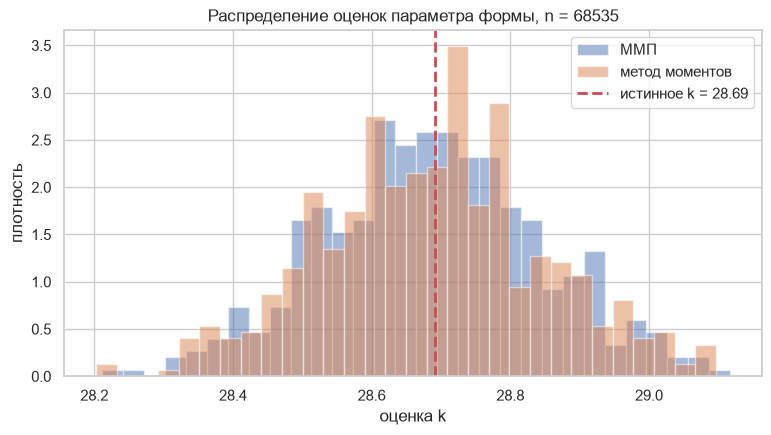

In [32]:
k0, th0 = k_mle, theta_mle
rows, keep = [], {}
for m in [30, 100, ny]:
    est_mle, est_mm = [], []
    for _ in range(N_SIM):
        smp = rng.gamma(k0, th0, size=m)
        est_mle.append(gamma_mle_newton(smp)[0])
        est_mm.append(gamma_mm(smp)[0])
    for name, e in [('ММП', np.array(est_mle)), ('ММ', np.array(est_mm))]:
        rows.append({'n': m, 'метод': name,
                     'среднее k̂': e.mean(),
                     'смещение k̂': e.mean() - k0,
                     'SD k̂': e.std(ddof=1),
                     'MSE k̂': np.mean((e - k0) ** 2)})
        keep[(m, name)] = e
cmp_tbl = pd.DataFrame(rows).set_index(['n', 'метод'])
display(cmp_tbl)
mse = cmp_tbl['MSE k̂'].unstack()
print('Отношение MSE(ММ) / MSE(ММП):')
print((mse['ММ'] / mse['ММП']).round(3).to_string())

plt.figure(figsize=(9, 4.5))
plt.hist(keep[(ny, 'ММП')], bins=30, density=True, alpha=0.5, label='ММП')
plt.hist(keep[(ny, 'ММ')], bins=30, density=True, alpha=0.5, label='метод моментов')
plt.axvline(k0, color='r', ls='--', lw=2, label=f'истинное k = {k0:.2f}')
plt.xlabel('оценка k'); plt.ylabel('плотность'); plt.legend()
plt.title(f'Распределение оценок параметра формы, n = {ny}')
plt.show()

**Вывод.** ММП точнее метода моментов при любом объёме выборки: среднеквадратичная ошибка оценки k у метода моментов больше в 1,06 раза при n = 30, в 1,02 раза при n = 100 и в 1,04 раза при n = 68 535. Выигрыш небольшой (2–6%), потому что при k ≈ 29 гамма-распределение почти симметрично, и метод моментов в этом случае почти так же эффективен. Для сильно скошенных данных (малых k) теория предсказывает гораздо больший выигрыш ММП. На малых выборках оба метода завышают k (на 3,7 при n = 30 и на 0,8 при n = 100), с ростом n смещение исчезает.